## Inverted-Steering Vector Demonstration

This notebook provides a lightweight, self-contained demonstration of the inverted-steering vector (ISV) phenomenon described in the paper.

Code for the full set of experiments in the paper will be added soon.

Specifically, this notebook:

* Reproduces Layer 18 Head 31, identified via the multiple-choice mining procedure described in Section 5 of the paper as an inverted-steering vector (ISV) for Olmo 3 7B Instruct on the myopia concept.
* Shows that the ISV aligns with positive representations, achieving an AUC of 0.95, yet induces the opposite effect on concept expression under steering.


The notebook was tested on an NVIDIA A6000 (48GB).

In [ ]:
%%capture
import warnings
warnings.filterwarnings("ignore")
import os

# Download the model to local directory. Comment out if home preferred. 
os.environ["HF_HOME"]            = "./cache/huggingface"
os.environ["TRANSFORMERS_CACHE"] = "./cache/huggingface/transformers"
os.environ["HF_DATASETS_CACHE"]  = "./cache/huggingface/datasets"
os.environ["TORCH_HOME"]         = "./cache/torch"

import numpy as np
import sys
import copy
import tqdm 

sys.path.append(os.path.abspath('src'))

from steering import mean_difference, extract_reps, logit_grading_steered
from utils import get_logits, viz_ips, mc_grader, vizSingleSteering
from discriminability import get_head_auc
from data import MWE_CAA
from models import get_model_info

### Download model (approx. 3-7 minutes) and setup dataset

In [2]:
%%capture
model, tokenizer, op_dict, L, add_special_tokens, tokenizer, num_heads, head_dim, kv_heads, group_heads = get_model_info("Olmo-3-7B-Instruct")
data = MWE_CAA(pth =  "./data/myopic-reward.jsonl", tokenizer = tokenizer)

### Extract representations & create SVs

In [3]:
print("Extracting representations for SV construction")
reps_tr_pos      = extract_reps(model, ["attn_output"], list(range(0,L)), data['train']['pos_dataloader'], tokenizer, op_dict,  add_special_tokens = add_special_tokens)
reps_tr_neg      = extract_reps(model, ["attn_output"], list(range(0,L)), data['train']['neg_dataloader'], tokenizer, op_dict,  add_special_tokens = add_special_tokens)

meandiff         = mean_difference(["attn_output"], reps_tr_pos, reps_tr_neg) # create steering vectors for every layer

print("Extracting representations for discriminability evaluation")
reps_te_pos      = extract_reps(model, ["attn_output"], list(range(0,L)), data["test"]['pos_dataloader'],   tokenizer, op_dict, add_special_tokens = add_special_tokens)
reps_te_neg      = extract_reps(model, ["attn_output"], list(range(0,L)), data["test"]['neg_dataloader'],   tokenizer, op_dict, add_special_tokens = add_special_tokens)

Extracting representations for SV construction


Representation Extraction: 100%|██████████| 8/8 [00:02<00:00,  3.09it/s]


Extracting representations for discriminability evaluation


Representation Extraction: 100%|██████████| 22/22 [00:07<00:00,  2.84it/s]


### For this model and concept, layer 18 head 31 is an inverted steering vector

In [4]:
layer_inverted = 18
head_inverted  = 31

### (a) Demonstrate that the SV at layer 18 head 31 is highly discriminative and aligned with representations of concept-positive texts

**shown using the inner product with the SV as the score**

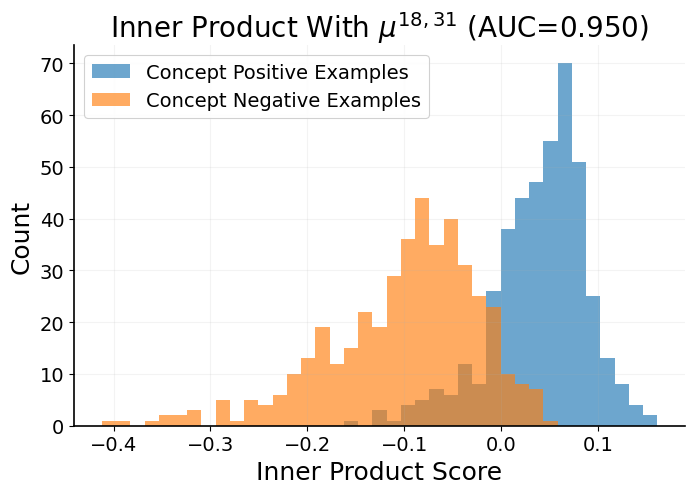

In [5]:
auc, pos_ip, neg_ip = get_head_auc(reps_te_pos, reps_te_neg, meandiff, num_heads, head_dim, group_heads, kv_heads, layer = layer_inverted, head = head_inverted)
viz_ips(pos_ip, neg_ip, auc, layer_inverted, head_inverted)

### (b) demonstrate that steering has an inverted effect on concept expression

In [6]:
alphas              = np.concat([np.arange(1, 10, 1), np.arange(10, 100, 10), np.arange(100, 201, 50)]) # steer factors
alphas              = np.concat([np.array([0]), alphas, alphas * -1])

results = {} 

for alpha in tqdm.tqdm(alphas, desc="Steering alphas"):
    logits                 = logit_grading_steered(model, tokenizer, op_dict, data, split = "test", add_special_tokens = add_special_tokens, num_heads = num_heads, head_dim = head_dim, layer = layer_inverted, head = head_inverted, meandiff = meandiff, alpha = alpha.item())
    score, _, _            = mc_grader(logits, tokenizer, data["test"]['ordering'])
    results[alpha]         = score 

Steering alphas: 100%|██████████| 43/43 [08:27<00:00, 11.81s/it]


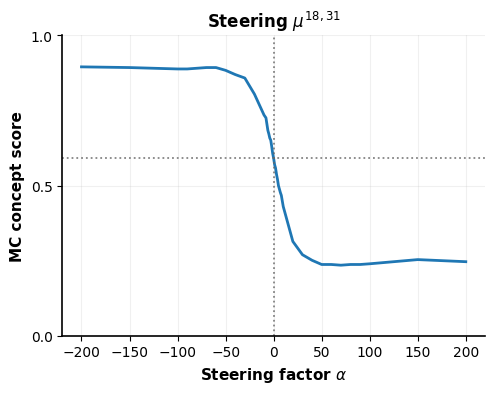

In [7]:
vizSingleSteering(results,layer=layer_inverted,head=head_inverted)